# Lab L3.2 · Behavioural customer segmentation with k-means and hierarchical clustering
**Horizon Gulf Bank · Project MIZAN** · CAIP AIP-210 · Certified AI Practitioner · Day 3 · ⏱ 45 min · **Level 3 · Complete solution**

Segment 250,000 customers on behaviour, choose k with evidence, validate with a second algorithm and turn clusters into named personas.

### Scenario
**Horizon Gulf Bank (HGB)** is a fictional UAE retail bank with 250,000 customers. Its Board approved **Project MIZAN** — an AI decisioning platform covering credit, fraud, collateral valuation, cash logistics, customer retention and document automation. You are a junior ML practitioner in the MIZAN squad.

The Retail Marketing team runs one-size-fits-all campaigns. They want 4–7 actionable segments with clear personas so that product offers, channel and retention budget can be tailored. There is no label — this is **unsupervised** learning.

**Progressive architecture:** uses your `customers_clean.parquet`; segments become an enrichment feature and a monitoring dimension later.

### Objectives
- Select and transform behavioural features for distance-based clustering
- Scale k-means to 250k rows with `MiniBatchKMeans`
- Choose k with inertia (elbow) and silhouette on a sample
- Profile and name clusters; check churn by segment *after* clustering
- Cross-check with Ward hierarchical clustering (adjusted Rand index) and visualise with PCA

In [1]:
# ── Project MIZAN course setup ─ run this cell first ──────────────────────────
from pathlib import Path
import warnings, time
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate the course root (the folder that contains data/generate_data.py) from wherever this notebook lives
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "generate_data.py").exists())
DATA = ROOT / "data"          # raw synthetic datasets (read-only)
CKPT = ROOT / "checkpoints"   # hand-off artefacts between labs (lets you start any lab fresh)
CKPT.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": .3})
RNG = 42
print("Course root:", ROOT)

Course root: C:\Users\Pushkar\Downloads\CAIP-AIP210-FINANCIAL-SERVICES-TRAINER-PACK\CAIP-AIP210-TopTier-Courseware


## Step 1 · Select and transform behavioural features

**Why this matters.** Segments should describe **behaviour** the bank can act on — balances, engagement, product holding — not protected attributes. Money variables are log-transformed (otherwise a few millionaires form their own clusters), then everything is standardised so each feature contributes equally to distance.

In [2]:
from sklearn.preprocessing import StandardScaler
cust = pd.read_parquet(CKPT / "customers_clean.parquet")
B = pd.DataFrame({
    "log_balance": np.log1p(cust.avg_balance_aed), "log_salary": np.log1p(cust.monthly_salary_aed),
    "tenure_months": cust.tenure_months, "num_products": cust.num_products,
    "digital_logins_30d": cust.digital_logins_30d, "branch_visits_90d": cust.branch_visits_90d,
    "card_spend_ratio": cust.card_spend_monthly_aed / cust.monthly_salary_aed,
    "log_days_since_txn": np.log1p(cust.days_since_last_txn), "complaints_12m": cust.complaints_12m})
Xs = StandardScaler().fit_transform(B)
pd.DataFrame(Xs, columns=B.columns).agg(["mean", "std"]).round(2)

,log_balance,log_salary,tenure_months,num_products,digital_logins_30d,branch_visits_90d,card_spend_ratio,log_days_since_txn,complaints_12m
mean,-0.0,-0.0,-0.0,0.0,-0.0,-0.0,0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


> **Think like a practitioner.** Why are `gender`, `nationality_group` and `age` *not* in the clustering features? Could you still describe segments by them afterwards?

## Step 2 · Choose k with elbow and silhouette

**Why this matters.** `MiniBatchKMeans` fits on mini-batches, making 250k rows fast. Silhouette is O(n²), so we score it on a 15k-row sample. We look for a k where inertia’s improvement slows and silhouette is still reasonable — within the 4–7 range Marketing can operationalise.

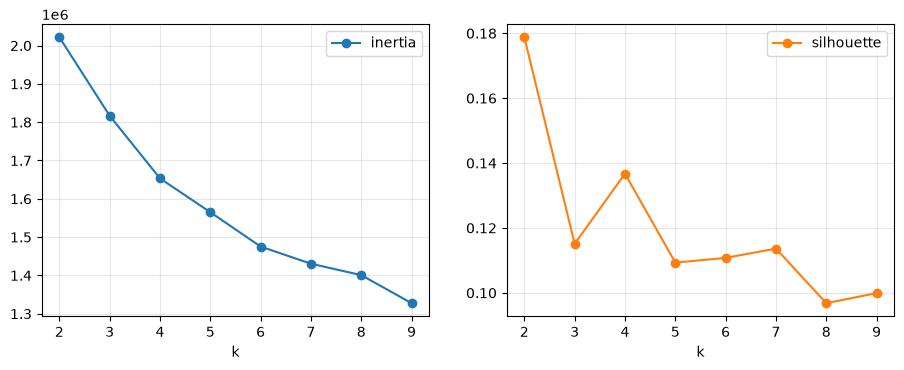

chosen K = 4


,inertia,silhouette
k,,
2,2021858.670,0.179
3,1816838.174,0.115
4,1653221.881,0.137
5,1564995.948,0.109
6,1475257.970,0.111
7,1430601.045,0.114
8,1400728.970,0.097
9,1327466.429,0.100


In [3]:
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score
idx = np.random.default_rng(RNG).choice(len(Xs), 15_000, replace=False)
rows = []
for k in range(2, 10):
    km = MiniBatchKMeans(n_clusters=k, batch_size=4096, n_init=5, random_state=RNG).fit(Xs)
    rows.append((k, km.inertia_, silhouette_score(Xs[idx], km.labels_[idx])))
sel = pd.DataFrame(rows, columns=["k", "inertia", "silhouette"]).set_index("k")
sel.plot(subplots=True, layout=(1, 2), marker="o", figsize=(11, 3.8)); plt.show()
K = int(sel.loc[4:7, "silhouette"].idxmax())
print("chosen K =", K); sel.round(3)

> **Think like a practitioner.** A silhouette of 0.15 is ‘weak structure’. Is the segmentation useless? (No — segments can be useful for action even when boundaries are fuzzy.)

## Step 3 · Fit, profile and name the segments

**Why this matters.** Clusters are only valuable once a human can describe them. A **profile** in original units plus a z-score heat-map makes the personas obvious. Churn was *not* used for clustering, so churn by segment is an honest test of business relevance.

,share,salary,balance,tenure,products,logins,branch,days_idle,churn_rate
segment,,,,,,,,,
0,0.15,12610.0,13401.99,41.0,2.42,20.32,0.58,4.0,0.18
1,0.39,9590.0,8247.31,36.0,2.02,20.83,0.54,4.0,0.14
2,0.13,12945.0,22100.49,124.0,2.58,20.61,0.55,4.0,0.04
3,0.32,21380.0,26316.12,38.0,3.05,19.34,0.72,4.0,0.10


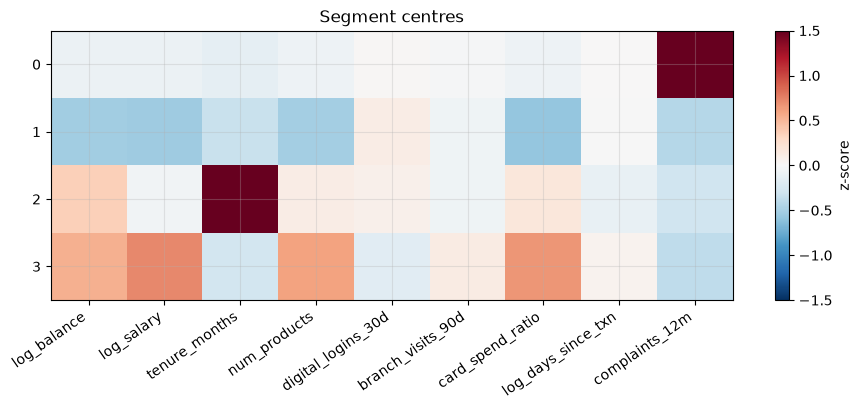

{0: 'high complaints_12m / low tenure_months',
 1: 'low card_spend_ratio / low log_salary',
 2: 'high tenure_months / high log_balance',
 3: 'high log_salary / high card_spend_ratio'}

In [4]:
km = MiniBatchKMeans(n_clusters=K, batch_size=4096, n_init=10, random_state=RNG).fit(Xs)
cust["segment"] = km.labels_
profile = cust.assign(**B).groupby("segment").agg(share=("customer_id", lambda s: len(s) / len(cust)),
    salary=("monthly_salary_aed", "median"), balance=("avg_balance_aed", "median"), tenure=("tenure_months", "median"),
    products=("num_products", "mean"), logins=("digital_logins_30d", "mean"), branch=("branch_visits_90d", "mean"),
    days_idle=("days_since_last_txn", "median"), churn_rate=("churned_6m", "mean"))
display(profile.round(2))
centres = pd.DataFrame(km.cluster_centers_, columns=B.columns)
plt.figure(figsize=(11, 3.5)); plt.imshow(centres, cmap="RdBu_r", vmin=-1.5, vmax=1.5, aspect="auto")
plt.xticks(range(B.shape[1]), B.columns, rotation=35, ha="right"); plt.yticks(range(K)); plt.colorbar(label="z-score"); plt.title("Segment centres"); plt.show()
PERSONA = {k: " / ".join(f"{'high' if centres.loc[k, c] > 0 else 'low'} {c}" for c in centres.loc[k].abs().nlargest(2).index) for k in range(K)}
cust["persona"] = cust.segment.map(PERSONA); PERSONA

## Step 4 · Cross-check with hierarchical clustering and PCA

**Why this matters.** If a different algorithm finds similar groups, the structure is real rather than an artefact of k-means. Ward linkage on a sample and the **adjusted Rand index** (0 = chance, 1 = identical) quantify the agreement. **PCA** gives a 2-D picture of the segments.

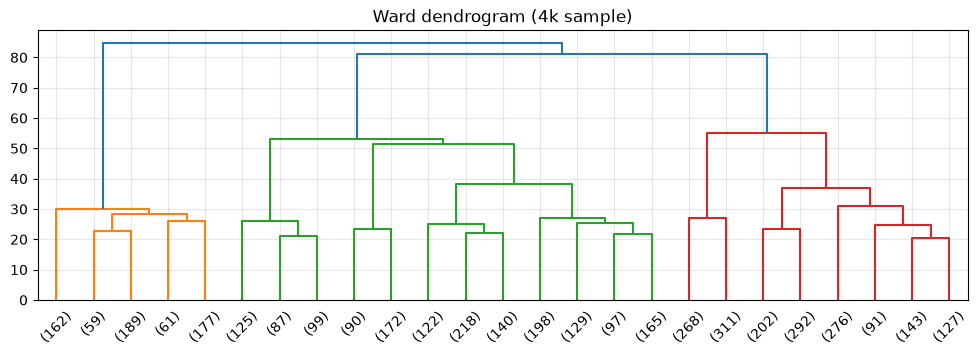

adjusted Rand index (Ward vs k-means): 0.404


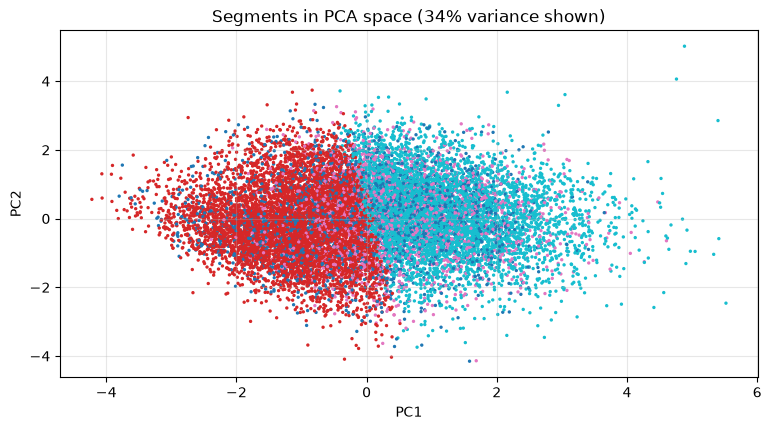

In [5]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.metrics import adjusted_rand_score
from sklearn.decomposition import PCA
h_idx = idx[:4000]
Z = linkage(Xs[h_idx], method="ward")
plt.figure(figsize=(12, 3.5)); dendrogram(Z, truncate_mode="lastp", p=25); plt.title("Ward dendrogram (4k sample)"); plt.show()
h_lab = fcluster(Z, t=K, criterion="maxclust")
print("adjusted Rand index (Ward vs k-means):", round(adjusted_rand_score(km.labels_[h_idx], h_lab), 3))
pca = PCA(n_components=2, random_state=RNG).fit(Xs)
P2 = pca.transform(Xs[idx[:20000]])
plt.scatter(P2[:, 0], P2[:, 1], c=km.labels_[idx[:20000]], s=2, cmap="tab10")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title(f"Segments in PCA space ({pca.explained_variance_ratio_.sum():.0%} variance shown)"); plt.show()

> **Think like a practitioner.** Only ~35% of variance is visible in 2-D. Why might clusters that overlap in the PCA plot still be well separated?

## Step 5 · Persist segments for downstream use

**Why this matters.** Segments become a feature for other models and a dimension for monitoring (e.g. fraud or churn rate by segment). We save the mapping and the fitted scaler + model so that new customers can be assigned consistently.

In [6]:
import joblib
seg = cust[["customer_id", "segment", "persona"]]
assert seg.customer_id.is_unique and seg.segment.notna().all()
seg.to_parquet(CKPT / "customer_segments.parquet", index=False)
joblib.dump({"features": list(B.columns), "kmeans": km}, CKPT / "segmentation_model.joblib")
seg.segment.value_counts(normalize=True).sort_index().round(3)

segment
0    0.153
1    0.393
2    0.131
3    0.323
Name: proportion, dtype: float64

## ✅ Lab complete
Marketing has data-driven personas. **Next:** fraud detection with decision trees and random forests at 1.5M-row scale.